<a href="https://colab.research.google.com/github/FrancoVenesia/TP_AA1_Perez_Venesia_Welsechen_CruzElizondoRios/blob/main/TP_2/TP-clasificacion-AA1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico 2: Predicción de lluvia en Australia
### Aprendizaje Automático I
### Facultad de Ciencias Exactas, Ingeniería y Agrimensura (FCEIA) - Universidad Nacional de Rosario (UNR)

### Integrantes:
- Welschen. Joaquín
- Venesia. Franco
- Elizondo Rios, Iñaki Cruz

Dataset: weatherAUS_2026C1.csv

## Consignas:
1. Realizar un análisis descriptivo, que ayude a la comprensión del problema, de cada
una de las variables involucradas, detallando: características, comportamiento y
rango de variación. ¿Qué es cada variable?
Debe incluir:
    -  Análisis y decisión sobre datos faltantes.
    -  Visualización de datos (por ejemplo histogramas, scatterplots entre variables,
    diagramas de caja)
    -  ¿Está balanceado el dataset? ¿Por qué cree que hacemos esta pregunta?
    -  Codificación de variables categóricas (si se van a utilizar para predicción).
    -  Matriz de correlación de variables.
    -  Estandarización/escalado de datos.
    -  Validación cruzada train - test. Realizar una división del conjunto de datos en conjuntos de entrenamiento y prueba (y si se quiere, se puede incluir
    validación, que luego será útil) en el MOMENTO donde lo crean adecuado.

2. Implementar la solución del problema de clasificación con regresión logística.
    - Obtener las métricas adecuadas (accuracy, precision, recall, F1 score, entre
    otras, ¡investiguen adicionales!). Graficar matrices de confusión para cada
    modelo. Analizar “falsos negativos” y “falsos positivos”, ¿qué significa cada
    uno?
    - Trazar curvas ROC para cada modelo. Comenten cuáles serían los umbrales
    adecuados a utilizar; ¿cómo podrían calcular el mejor umbral? ¿Es 0.5 el
    mejor?
    - ¿Creen que han conseguido un buen fitting?

## 0. Librerias

In [117]:
import pandas as pd
pd.set_option('display.max_columns', None)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Analisis descriptivo

### 1.1 Exploracion y limpieza de datos

#### 1.1.1 Carga y primera inspeccion

In [118]:
# LA SERIE DE TIEMPO CUIDADO AL DIVIDIR EN TRAIN TEST VAL, ORDENAR EL DATASET EN EJEMPLO 6, 2, 2 AÑOS
# SIN COS PARA VARIABLES CATEGORICAS
# ITEM 3 ES REPETIR EL ITEM 2

In [119]:
df = pd.read_csv('weatherAUS_2026C2.csv')

#Dimensiones del dataset
print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')


df.head(10)

Filas: 145412 | Columnas: 25


,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,W,WNW,19.0,25.0,68.8,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,23.0,40.1,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,W,WSW,20.0,27.0,36.2,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,SE,E,10.0,10.0,45.8,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,ENE,NW,6.0,17.0,83.5,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
5,5,2008-12-06,Albury,14.5,30.1,0.2,NaN,NaN,WNW,55.0,W,W,19.0,24.0,56.6,23.0,1009.9,1005.5,NaN,NaN,20.9,28.2,No,No,0.0
6,6,2008-12-07,Albury,15.1,25.3,0.0,NaN,NaN,W,51.0,SW,W,21.0,24.0,46.8,20.3,1009.3,1008.5,1.0,NaN,18.3,24.0,No,No,0.0
7,7,2008-12-08,Albury,8.1,26.1,0.0,NaN,NaN,W,34.0,SSE,W,5.0,16.0,46.8,20.8,1013.5,1009.7,NaN,NaN,17.1,25.9,No,No,0.0
8,8,2008-12-09,Albury,9.5,31.8,0.0,NaN,NaN,NNW,80.0,SE,NW,6.0,28.0,42.1,8.5,1008.9,1003.6,NaN,NaN,18.0,28.9,No,Yes,1.4
9,9,2008-12-10,Albury,13.4,30.1,1.4,NaN,NaN,W,28.0,S,SSE,14.0,12.0,57.6,24.6,1007.2,1005.7,NaN,NaN,18.9,28.2,Yes,No,0.0


In [120]:
#Informacion de tipos de datos y Cantidad de valores no nulos por columna
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  object 
 2   Location          145412 non-null  object 
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  object 
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  object 
 11  WindDir3pm        141186 non-null  object 
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       13

#### 1.1.2 Diccionario de variables (Qué son los datos?)

Cada fila es una observación diaria de una estación meteorológica. Las variables son:

| Variable | Descripción | Tipo | Unidad |
|---|---|---|---|
| `Unnamed: 0` | Índice de fila del archivo original. No aporta información. | entero | - |
| `Date` | Fecha de la observación. | fecha | - |
| `Location` | Ciudad / estación donde se tomó la observación (49 distintas). | categórica nominal | - |
| `MinTemp` | Temperatura mínima del día. | numérica continua | °C |
| `MaxTemp` | Temperatura máxima del día. | numérica continua | °C |
| `Rainfall` | Lluvia caída en las 24 h previas a las 9 am. | numérica continua | mm |
| `Evaporation` | Evaporación (tanque clase A) en las 24 h previas a las 9 am. | numérica continua | mm |
| `Sunshine` | Horas de sol del día. | numérica continua | horas |
| `WindGustDir` | Dirección de la ráfaga de viento más fuerte del día (16 puntos cardinales). | categórica nominal | - |
| `WindGustSpeed` | Velocidad de esa ráfaga máxima. | numérica continua | km/h |
| `WindDir9am`, `WindDir3pm` | Dirección del viento a las 9 am y a las 3 pm. | categórica nominal | - |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad media del viento en los 10 minutos previos a las 9 am / 3 pm. | numérica continua | km/h |
| `Humidity9am`, `Humidity3pm` | Humedad relativa a las 9 am / 3 pm. | numérica continua | % |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica reducida al nivel del mar a las 9 am / 3 pm. | numérica continua | hPa |
| `Cloud9am`, `Cloud3pm` | Fracción del cielo cubierta por nubes a las 9 am / 3 pm. | numérica discreta (0 a 8) | octas |
| `Temp9am`, `Temp3pm` | Temperatura a las 9 am / 3 pm. | numérica continua | °C |
| `RainToday` | `Yes` si `Rainfall` supera 1 mm, `No` en otro caso. | categórica binaria | - |
| `RainTomorrow` | **Variable objetivo**: `Yes` si al día siguiente llovió más de 1 mm. | categórica binaria | - |
| `RainfallTomorrow` | Lluvia caída al día siguiente. | numérica continua | mm |

`RainfallTomorrow` es lo que queremos predecir: a las 23:59 no la conocemos y `RainTomorrow` se calcula directamente a partir de ella.

Si la dejamos, el modelo tendría información que no va a estar disponible al momento de predecir (fuga de datos), así que la eliminamos. El resto de las variables sí se conocen a las 23:59 del día.

También eliminamos `Unnamed: 0`, que es solamente un índice.


### 1.1.2 Limpieza inicial

In [121]:
# Verificación del leakage entre RainfallTomorrow y RainTomorrow
# Comprobamos la relación entre ambas columnas
check = df.dropna(subset=['RainTomorrow', 'RainfallTomorrow']).copy()
check['rainfall_geq_1'] = (check['RainfallTomorrow'] >= 1).map({True: 'Yes', False: 'No'})

print("Tabla cruzada entre 'RainfallTomorrow >= 1' y 'RainTomorrow':")
print(pd.crosstab(check['rainfall_geq_1'], check['RainTomorrow']))

print("\n¿Coinciden en todos los casos?:",
      (check['rainfall_geq_1'] == check['RainTomorrow']).mean())

Tabla cruzada entre 'RainfallTomorrow >= 1' y 'RainTomorrow':
RainTomorrow        No    Yes
rainfall_geq_1               
No              108522      0
Yes               1759  31872

¿Coinciden en todos los casos?: 0.9876260085963715


In [122]:
# Eliminamos el índice y la variable con data leakage
df = df.drop(columns=['Unnamed: 0', 'RainfallTomorrow'])

Se elimina las filas que no contengan valor en la variable objetivo

In [123]:
# Filas sin variable objetivo: no sirven para entrenar ni para evaluar
print('Filas sin RainTomorrow:', df['RainTomorrow'].isna().sum(), f"({df['RainTomorrow'].isna().mean():.1%})")
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
print(df.shape)

Filas sin RainTomorrow: 3259 (2.2%)
(142153, 23)


In [124]:
# Pasamos la fecha a datetime y extraemos el mes, que usaremos para capturar la estacionalidad
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month

Se ordena el dataset por fecha para luego realizar la division del mismo

In [125]:
df = df.sort_values(by='Date').reset_index(drop=True)
print("Rango de fechas después de ordenar:", df['Date'].min(), "a", df['Date'].max())

Rango de fechas después de ordenar: 2007-11-01 00:00:00 a 2017-06-24 00:00:00


In [126]:
# Consistencia: duplicados y relación entre Rainfall y RainToday
print('Filas duplicadas:', df.duplicated().sum())
print('Fecha y ciudad repetidas:', df.duplicated(['Date', 'Location']).sum())
con_dato = df['Rainfall'].notna() & df['RainToday'].notna()
print('RainToday coincide con Rainfall > 1 mm:', ((df['Rainfall'] > 1) == (df['RainToday'] == 'Yes'))[con_dato].mean())
print('Días con MinTemp > MaxTemp:', (df['MinTemp'] > df['MaxTemp']).sum())

Filas duplicadas: 0
Fecha y ciudad repetidas: 0
RainToday coincide con Rainfall > 1 mm: 1.0
Días con MinTemp > MaxTemp: 68


No hay filas duplicadas y `RainToday` es siempre consistente con `Rainfall` (vale `Yes` exactamente cuando llovió más de 1 mm). Esto nos sirve más adelante para completar `RainToday` cuando falta.

Hay unos pocos días donde la mínima supera a la máxima. Las diferencias son de décimas de grado y se explican porque la mínima y la máxima se registran en ventanas de 24 h distintas, así que no las consideramos errores y las dejamos.

#### Cambio de variables

Se codifican las variables categoricas en valores binarios

In [127]:
# Se reemplaza por valores binarios
df['RainTomorrow'] = df['RainTomorrow'].astype(str).str.strip().str.title().replace({'Yes': 1, 'No': 0})
df['RainToday'] = df['RainToday'].astype(str).str.strip().str.title().replace({'Yes': 1, 'No': 0})

# Verificamos
print('RainTomorrow:')
print(df['RainTomorrow'].value_counts(dropna=False))
print('\nRainToday:')
print(df['RainToday'].value_counts(dropna=False))

RainTomorrow:
RainTomorrow
0    110281
1     31872
Name: count, dtype: int64

RainToday:
RainToday
0      109296
1       31451
Nan      1406
Name: count, dtype: int64


Se obtiene el dia del año y se codifica de manera cíclica

In [128]:
# Extraemos el día del año (1-365/366)
df['DayOfYear'] = df['Date'].dt.dayofyear

# Codificación cíclica: mapea el día del año a un punto del círculo unitario
df['DayOfYear_sin'] = np.sin(2 * np.pi * df['DayOfYear'] / 365)
df['DayOfYear_cos'] = np.cos(2 * np.pi * df['DayOfYear'] / 365)

# Codificación cíclica del mes
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

# Eliminamos las columnas auxiliares: Date original ya no la necesitamos,
# y DayOfYear queda reemplazada por sus componentes cíclicas
#df = df.drop(columns=['Date', 'DayOfYear'])

df.tail()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month,DayOfYear,DayOfYear_sin,DayOfYear_cos,Month_sin,Month_cos
142148,2017-06-24,Watsonia,6.2,11.6,3.2,1.8,5.6,SSW,24.0,WNW,SW,9.0,10.0,98.1,59.0,1018.5,1017.3,2.0,7.0,8.5,11.0,1,0,6,175,0.128748,-0.991677,1.224647e-16,-1.0
142149,2017-06-24,Dartmoor,6.8,11.9,3.0,NaN,NaN,W,21.0,NW,WNW,0.0,11.0,97.4,68.3,1020.0,1017.3,NaN,NaN,7.2,11.0,1,0,6,175,0.128748,-0.991677,1.224647e-16,-1.0
142150,2017-06-24,Brisbane,10.3,24.5,0.0,3.4,8.9,S,17.0,S,WNW,1.0,0.0,73.7,33.0,1018.8,1015.7,7.0,5.0,14.8,23.5,0,0,6,175,0.128748,-0.991677,1.224647e-16,-1.0
142151,2017-06-24,GoldCoast,12.1,23.9,0.0,NaN,NaN,SE,31.0,WNW,ENE,16.0,13.0,66.0,50.9,1017.7,1014.8,NaN,NaN,17.4,22.4,0,0,6,175,0.128748,-0.991677,1.224647e-16,-1.0
142152,2017-06-24,Uluru,7.5,26.5,0.0,NaN,NaN,SE,28.0,SSE,N,13.0,7.0,52.1,27.1,1019.8,1016.2,3.0,2.0,14.7,26.8,0,0,6,175,0.128748,-0.991677,1.224647e-16,-1.0


#### Conociendo los datos

In [129]:
#Estadisticas variables numericas

df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,142153,2013-03-31 14:02:26.124246272,2007-11-01 00:00:00,2011-01-05 00:00:00,2013-05-27 00:00:00,2015-06-12 00:00:00,2017-06-24 00:00:00,NaN
MinTemp,141516.0,12.188866,-9.7,7.6,12.0,16.8,34.1,6.422856
MaxTemp,141831.0,23.228596,-5.1,17.9,22.6,28.2,49.1,7.134436
Rainfall,140747.0,2.350461,0.0,0.0,0.0,0.8,371.0,8.466267
Evaporation,81341.0,5.470149,0.0,2.6,4.8,7.4,145.0,4.188649
Sunshine,74368.0,7.624919,0.0,4.9,8.5,10.6,14.5,3.781656
WindGustSpeed,132885.0,39.985807,6.0,31.0,38.0,48.0,135.0,13.630314
WindSpeed9am,140805.0,14.025219,0.0,7.0,13.0,19.0,130.0,8.914326
WindSpeed3pm,139524.0,18.636901,0.0,12.0,18.0,24.0,86.0,8.858849
Humidity9am,140379.0,68.824619,0.0,56.9,69.9,83.1,100.0,19.085026


Observaciones:

- Temperatura: Rango amplio desde -10°C hasta 49°C
- Precipitación (Rainfall): Alta variabilidad, mayoría de días sin lluvia  (mediana = 0)
- Humedad: Valores entre 0-100%, con mayor humedad en la mañana (9am)
- Viento: Velocidades variables, ráfagas pueden superar 100 km/h
- Presión atmosférica: Relativamente estable, rango \~980-1040 hPa

In [130]:
#Estadisticas variables categóricas

df.describe(include='object').T

,count,unique,top,freq
Location,142153,49,Canberra,3417
WindGustDir,132825,16,W,9775
WindDir9am,132144,16,N,11389
WindDir3pm,138377,16,SE,10662
RainToday,142153,3,0,109296


Se analiza el porcentaje de nulos

In [131]:
# Resumen consolidado: nulos, % nulos, valores únicos
resumen = pd.DataFrame({
    'No_Nulos': df.notnull().sum(),
    'Nulos': df.isnull().sum(),
    '%_Nulos': (df.isnull().sum() / len(df) * 100).round(2),
    'Valores_Unicos': df.nunique()
})
resumen = resumen[resumen['Nulos'] > 0].sort_values('%_Nulos', ascending=False)
resumen

,No_Nulos,Nulos,%_Nulos,Valores_Unicos
Sunshine,74368,67785,47.68,145
Evaporation,81341,60812,42.78,356
Cloud3pm,85077,57076,40.15,10
Cloud9am,88512,53641,37.73,10
Pressure9am,128143,14010,9.86,547
Pressure3pm,128176,13977,9.83,542
WindDir9am,132144,10009,7.04,16
WindGustDir,132825,9328,6.56,16
WindGustSpeed,132885,9268,6.52,120
WindDir3pm,138377,3776,2.66,16


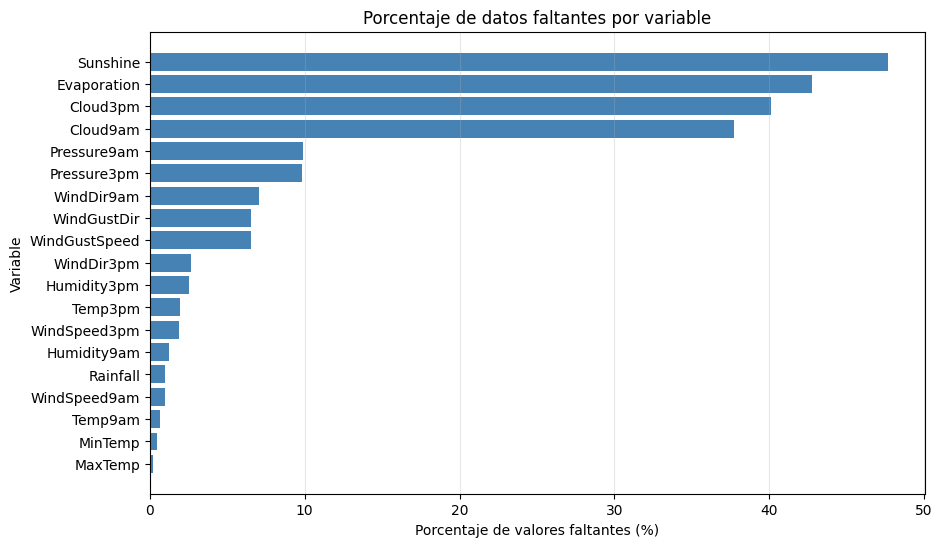

In [132]:
# Visualización de faltantes
plt.figure(figsize=(10, 6))
plt.barh(resumen.index, resumen['%_Nulos'], color='steelblue')
plt.xlabel('Porcentaje de valores faltantes (%)')
plt.ylabel('Variable')
plt.title('Porcentaje de datos faltantes por variable')
plt.gca().invert_yaxis()  # mayor arriba
plt.grid(True, alpha=0.3, axis='x')


Las variables con gran cantidad de datos faltantes son: Sunshine (\~48%), Evaporation (\~43%), Cloud (~40%)

Se analizan la proporción de valores faltantes por variable y ciudad

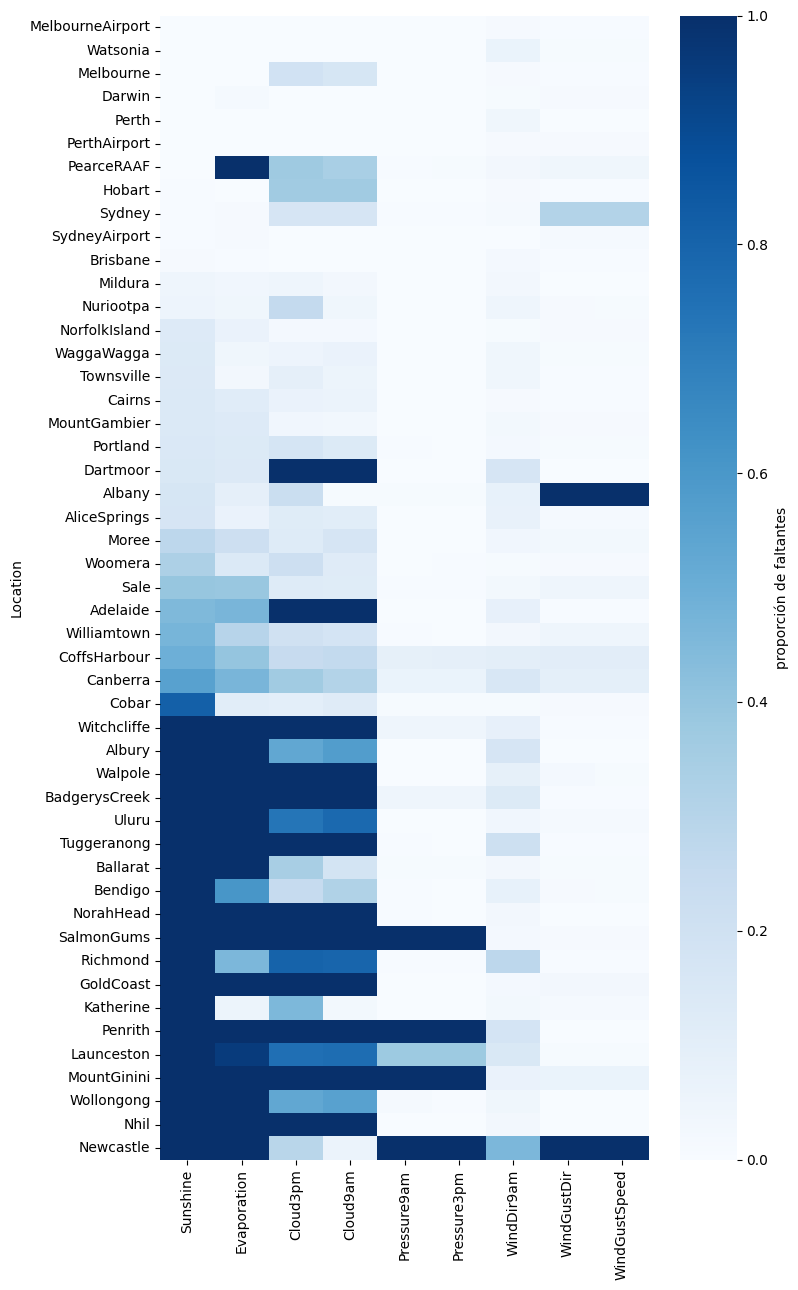

In [133]:
# Proporción de faltantes por ciudad para las variables más incompletas
cols_falt = ['Sunshine', 'Evaporation', 'Cloud3pm', 'Cloud9am', 'Pressure9am', 'Pressure3pm','WindDir9am', 'WindGustDir', 'WindGustSpeed']
falt_ciudad = df.groupby('Location')[cols_falt].apply(lambda g: g.isna().mean())
fig, ax = plt.subplots(figsize=(8, 13))
sns.heatmap(falt_ciudad.sort_values('Sunshine'), cmap='Blues', vmin=0, vmax=1,
            cbar_kws={'label': 'proporción de faltantes'}, ax=ax)
plt.tight_layout()
plt.show()

Podemos concluir que hay gran cantidad de valores nulos para ciertas ciudades, por lo que a la hora de imputar se debe considerar agrupar por valores climaticos similares

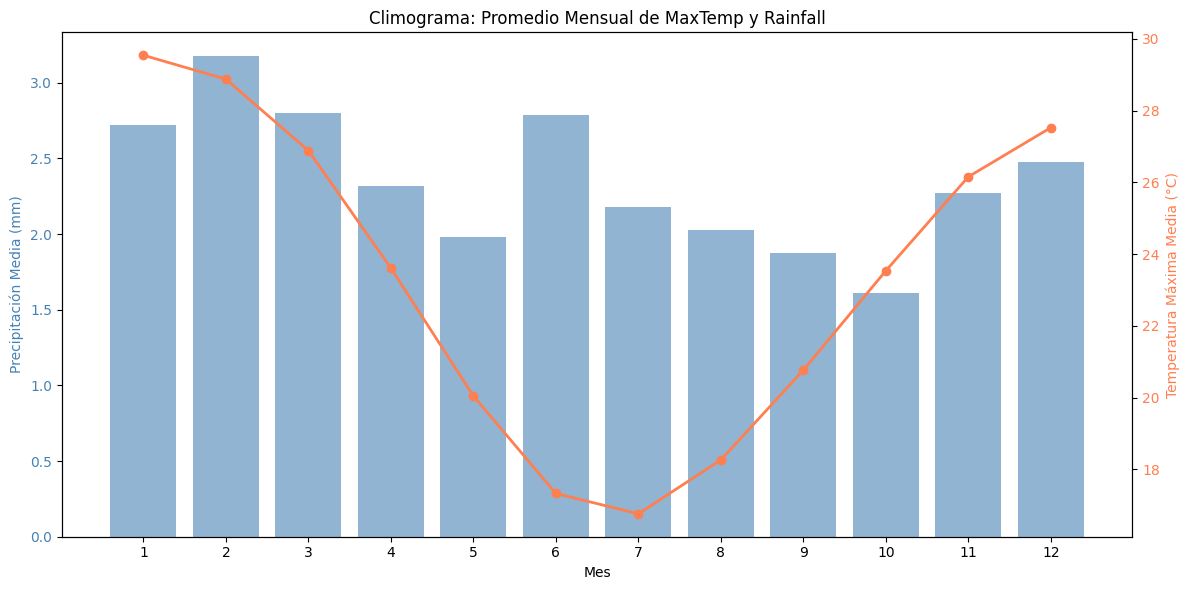

In [134]:
# Se calcula las medias mensuales
monthly_data = df.groupby('Month').agg({'MaxTemp': 'mean', 'Rainfall': 'mean'}).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje primario para la Precipitación
color_rain = 'steelblue'
ax1.set_xlabel('Mes')
ax1.set_ylabel('Precipitación Media (mm)', color=color_rain)
ax1.bar(monthly_data['Month'], monthly_data['Rainfall'], color=color_rain, alpha=0.6, label='Rainfall')
ax1.tick_params(axis='y', labelcolor=color_rain)
ax1.set_xticks(range(1, 13))

# Eje secundario para la Temperatura
ax2 = ax1.twinx()
color_temp = 'coral'
ax2.set_ylabel('Temperatura Máxima Media (°C)', color=color_temp)
ax2.plot(monthly_data['Month'], monthly_data['MaxTemp'], color=color_temp, marker='o', linewidth=2, label='MaxTemp')
ax2.tick_params(axis='y', labelcolor=color_temp)

plt.title('Climograma: Promedio Mensual de MaxTemp y Rainfall')
fig.tight_layout()
plt.show()

Agrupación de las estaciones meteorológicas según los criterios científicos oficiales de la [Oficina de Meteorología de Australia (BOM)](https://www.bom.gov.au/resources/learn-and-explore/climate-knowledge-centre/australian-climate-zones)

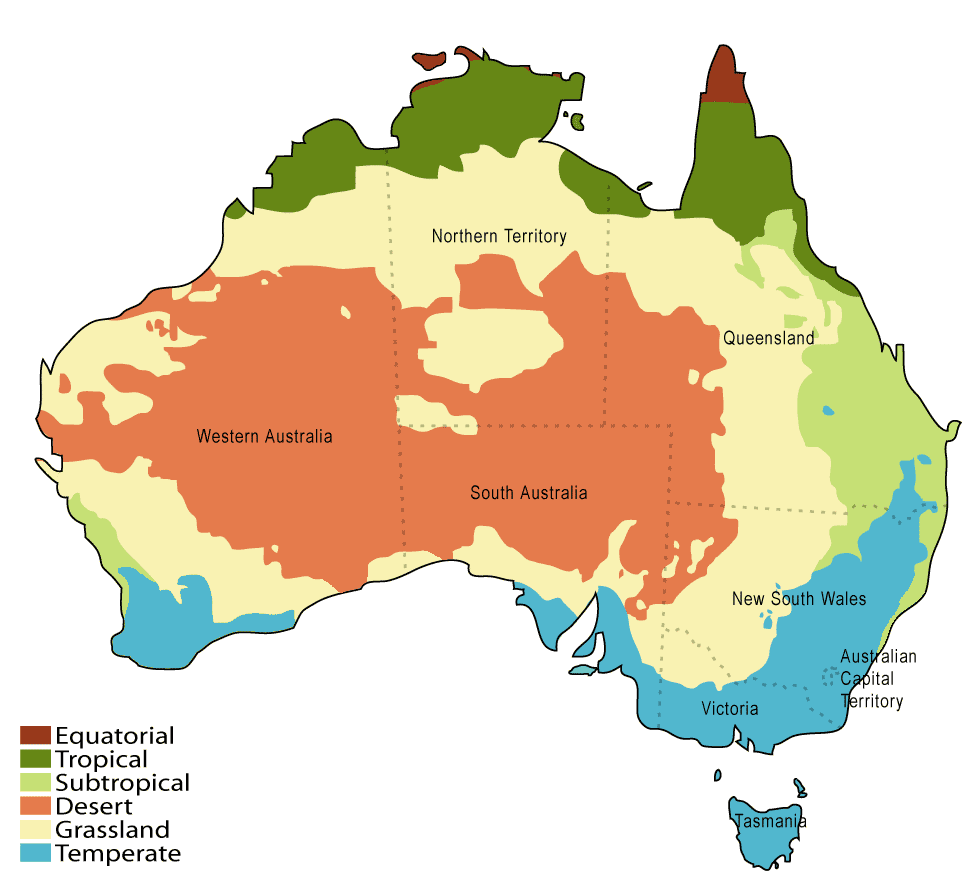

Se agrupan las 49 localidades originales en 7 macro-regiones climáticas basadas en los criterios del BOM, se reduce drásticamente la cardinalidad de la variable espacial.

In [135]:
regiones_climaticas = {
    'Tropical': {
        # Región caracterizada por altas temperaturas todo el año, lluvias intensas en verano y ciclones.
        'Cairns':           (-16.9186, 145.7781),
        'Darwin':           (-12.4634, 130.8456),
        'Katherine':        (-14.4651, 132.2635),
        'Townsville':       (-19.2589, 146.8169)
    },

    'Subtropical': { # (Costa Este)
        # Humedad elevada, veranos cálidos con precipitaciones y estabilidad térmica invernal.
        'Brisbane':         (-27.4698, 153.0251),
        'CoffsHarbour':     (-30.2963, 153.1135),
        'GoldCoast':        (-28.0167, 153.4000),
        'NorfolkIsland':    (-29.0408, 167.9547)  # Territorio marítimo subtropical
    },

    'Desértica': { # (Centro)
        # Precipitaciones ínfimas (<250mm anuales), amplitudes térmicas extremas día/noche.
        'AliceSprings':     (-23.6980, 133.8807),
        'Uluru':            (-25.3444, 131.0369),
        'Woomera':          (-31.1997, 136.8253)
    },

    'Pastizales': { # (Estepa de Transición)
        # Clima seco que rodea los desiertos; alta variabilidad y propenso a sequías estacionales.
        'Cobar':            (-31.4980, 145.8347),
        'Mildura':          (-34.2080, 142.1246),
        'Moree':            (-29.4640, 149.8344),
        'Nhil':             (-36.3328, 141.6503),
        'SalmonGums':       (-32.9815, 121.6438)
    },

    'Templada': { # (Costa Sur y Sureste)
        # Cuatro estaciones bien marcadas. Veranos templados/cálidos e inviernos frescos. Concentra la mayoría de las estaciones.
        'Adelaide':         (-34.9285, 138.6007),
        'Albury':           (-36.0737, 146.9135),
        'BadgerysCreek':    (-33.8830, 150.7717),
        'Ballarat':         (-37.5622, 143.8503),
        'Bendigo':          (-36.7570, 144.2794),
        'Canberra':         (-35.2809, 149.1300),
        'Dartmoor':         (-37.9220, 141.2760),
        'Hobart':           (-42.8821, 147.3272),
        'Launceston':       (-41.4332, 147.1441),
        'Melbourne':        (-37.8136, 144.9631),
        'MelbourneAirport': (-37.6733, 144.8433),
        'Newcastle':        (-32.9283, 151.7817),
        'NorahHead':        (-33.2833, 151.5667),
        'Nuriootpa':        (-34.4667, 138.9833),
        'Penrith':          (-33.7510, 150.6940),
        'Richmond':         (-33.5996, 150.7510),
        'Sale':             (-38.1051, 147.0658),
        'Sydney':           (-33.8688, 151.2093),
        'SydneyAirport':    (-33.9399, 151.1753),
        'Tuggeranong':      (-35.4156, 149.0888),
        'WaggaWagga':       (-35.1082, 147.3598),
        'Watsonia':         (-37.7110, 145.0830),
        'Williamtown':      (-32.8150, 151.8428),
        'Wollongong':       (-34.4278, 150.8931)
    },

    'Oceánica': { # (Sudoeste y Costa Sur Fría)
        # Inviernos muy lluviosos por frentes antárticos y veranos secos (típico del sudoeste de WA y franja sur costera).
        'Albany':           (-35.0269, 117.8837),
        'MountGambier':     (-37.8284, 140.7804),
        'PearceRAAF':       (-31.6676, 116.0292),
        'Perth':            (-31.9505, 115.8605),
        'PerthAirport':     (-31.9403, 115.9669),
        'Portland':         (-38.3457, 141.6042),
        'Walpole':          (-34.9777, 116.7338),
        'Witchcliffe':      (-34.0261, 115.1005)
    },

    'Montañoso': {
        # Microclima específico de alta montaña, temperaturas invernales bajo cero y precipitaciones en forma de nieve.
        'MountGinini':      (-35.5294, 148.7723)
    }
}

# Ciudad -> Región Climática.
mapeo_ciudad_region = {
    ciudad: region
    for region, ciudades in regiones_climaticas.items()
    for ciudad in ciudades
}

df['Region_BOM'] = df['Location'].map(mapeo_ciudad_region)

print(f'Distribución de observaciones por región BOM:')
print(df['Region_BOM'].value_counts())
df.head()

Distribución de observaciones por región BOM:
Region_BOM
Templada       71743
Oceánica       23770
Pastizales     13368
Subtropical    12054
Tropical       10770
Desértica       7542
Montañoso       2906
Name: count, dtype: int64


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month,DayOfYear,DayOfYear_sin,DayOfYear_cos,Month_sin,Month_cos,Region_BOM
0,2007-11-01,Canberra,7.9,24.3,0.0,3.4,6.3,NW,29.0,SW,NW,7.0,20.0,63.9,28.1,1020.3,1014.7,7.0,7.0,14.4,23.5,0,1,11,305,-0.858764,0.512371,-0.5,0.866025,Templada
1,2007-11-02,Canberra,13.3,27.0,3.6,4.4,9.7,ENE,38.0,E,W,5.0,14.0,79.4,35.8,1012.1,1008.5,5.0,3.0,17.4,25.6,1,1,11,306,-0.849817,0.527078,-0.5,0.866025,Templada
2,2007-11-03,Canberra,13.9,23.1,3.6,5.8,3.3,NW,84.0,N,NNE,5.0,6.0,80.9,68.8,1009.6,1007.4,8.0,7.0,15.3,20.0,1,1,11,307,-0.840618,0.541628,-0.5,0.866025,Templada
3,2007-11-04,Canberra,13.0,15.8,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,23.0,62.7,55.9,1005.4,1007.0,2.0,7.0,13.1,13.3,1,1,11,308,-0.831171,0.556017,-0.5,0.866025,Templada
4,2007-11-05,Canberra,7.8,16.4,2.8,5.6,10.6,SSE,49.0,SSE,ESE,19.0,28.0,67.5,50.1,1018.4,1018.6,7.0,7.0,11.4,15.9,1,0,11,309,-0.821477,0.570242,-0.5,0.866025,Templada


Climograma para las distintas regiones

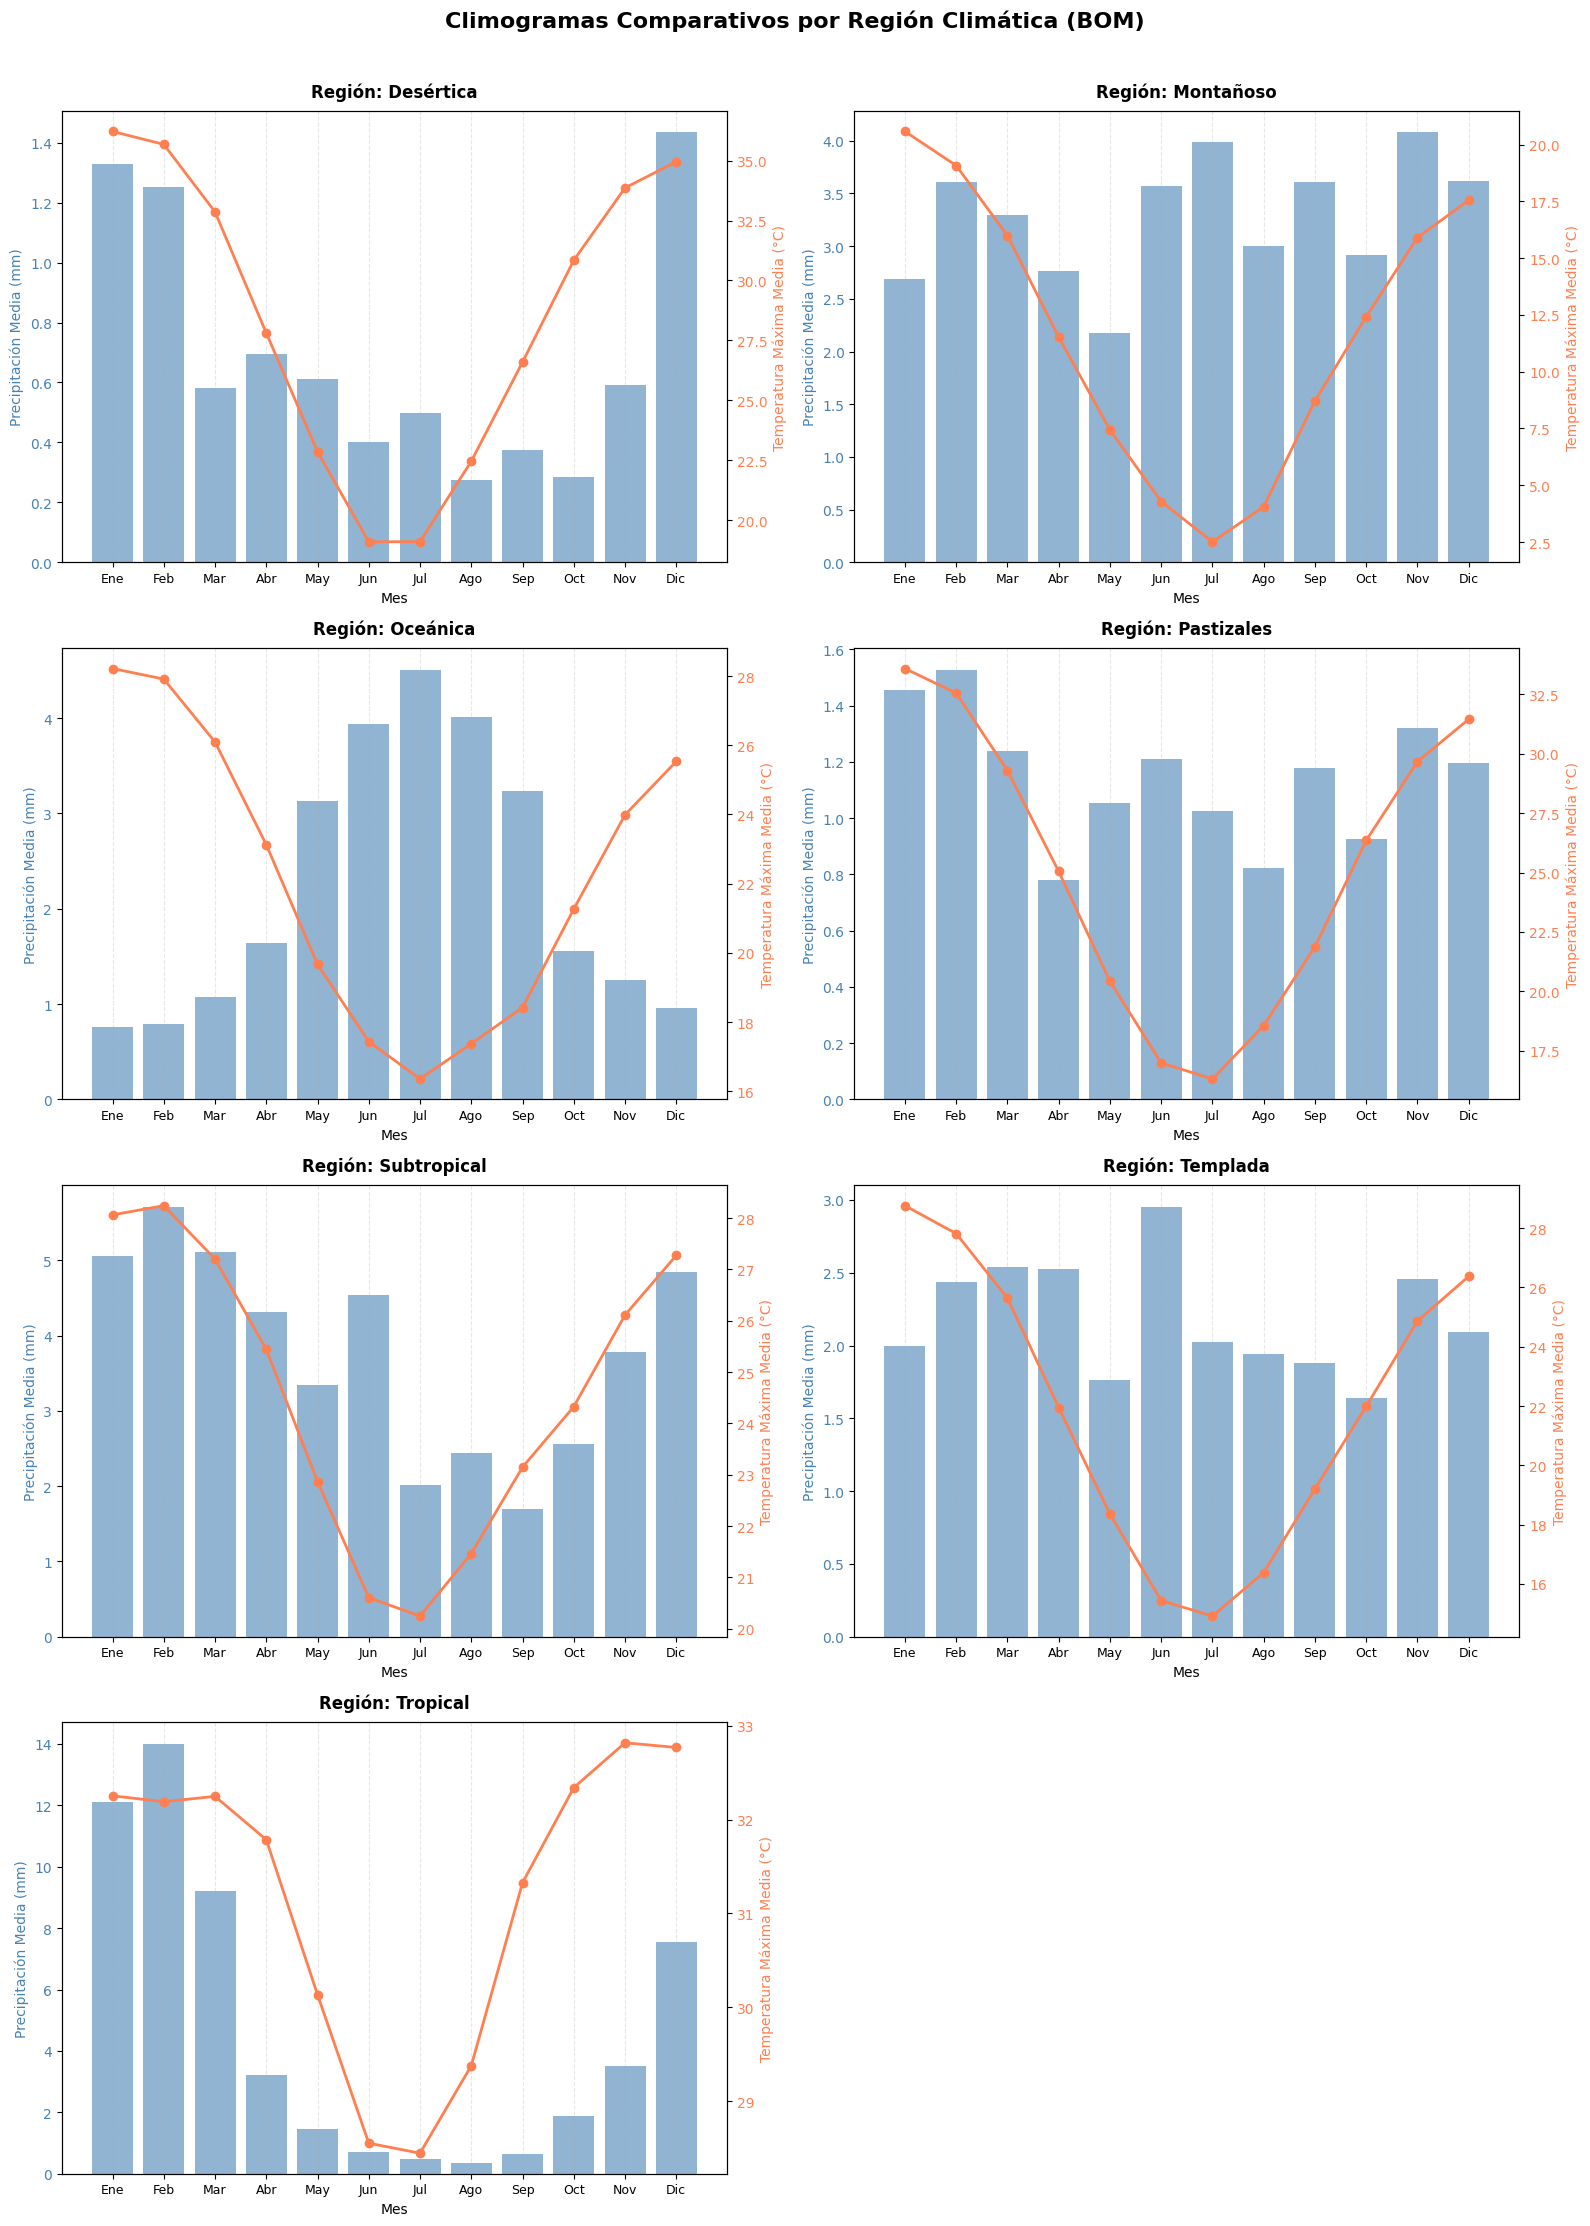

In [136]:

# Se agrupa los datos simultáneamente por Región y por Mes para calcular las medias correspondientes
monthly_data = df.groupby(['Region_BOM', 'Month']).agg({'MaxTemp': 'mean', 'Rainfall': 'mean'}).reset_index()

regiones = monthly_data['Region_BOM'].dropna().unique()
num_regiones = len(regiones)

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 22), sharex=False)
axes = axes.flatten()

color_rain = 'steelblue'
color_temp = 'coral'

# Construcción del climograma para cada región climática
for i, region in enumerate(regiones):
    ax1 = axes[i]

    data_region = monthly_data[monthly_data['Region_BOM'] == region].sort_values('Month')

    # --- Eje Primario (Izquierdo): Precipitación ---
    ax1.bar(data_region['Month'], data_region['Rainfall'], color=color_rain, alpha=0.6, label='Precipitación')
    ax1.set_ylabel('Precipitación Media (mm)', color=color_rain, fontsize=10)
    ax1.tick_params(axis='y', labelcolor=color_rain)
    ax1.set_xticks(range(1, 13))
    ax1.set_xticklabels(['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'], fontsize=9)
    ax1.set_xlabel('Mes', fontsize=10)

    # --- Eje Secundario (Derecho): Temperatura Máxima ---
    ax2 = ax1.twinx()
    ax2.plot(data_region['Month'], data_region['MaxTemp'], color=color_temp, marker='o', linewidth=2, label='Temp Máx')
    ax2.set_ylabel('Temperatura Máxima Media (°C)', color=color_temp, fontsize=10)
    ax2.tick_params(axis='y', labelcolor=color_temp)

    # Personalización estética de cada panel
    ax1.set_title(f'Región: {region}', fontsize=12, fontweight='bold', pad=10)
    ax1.grid(True, linestyle='--', alpha=0.3, axis='x')

for j in range(num_regiones, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Climogramas Comparativos por Región Climática (BOM)', fontsize=16, fontweight='bold', y=1.01)
fig.tight_layout()

## hacer comentario sobre las distintas regiones

Distribucion de las variables numericas

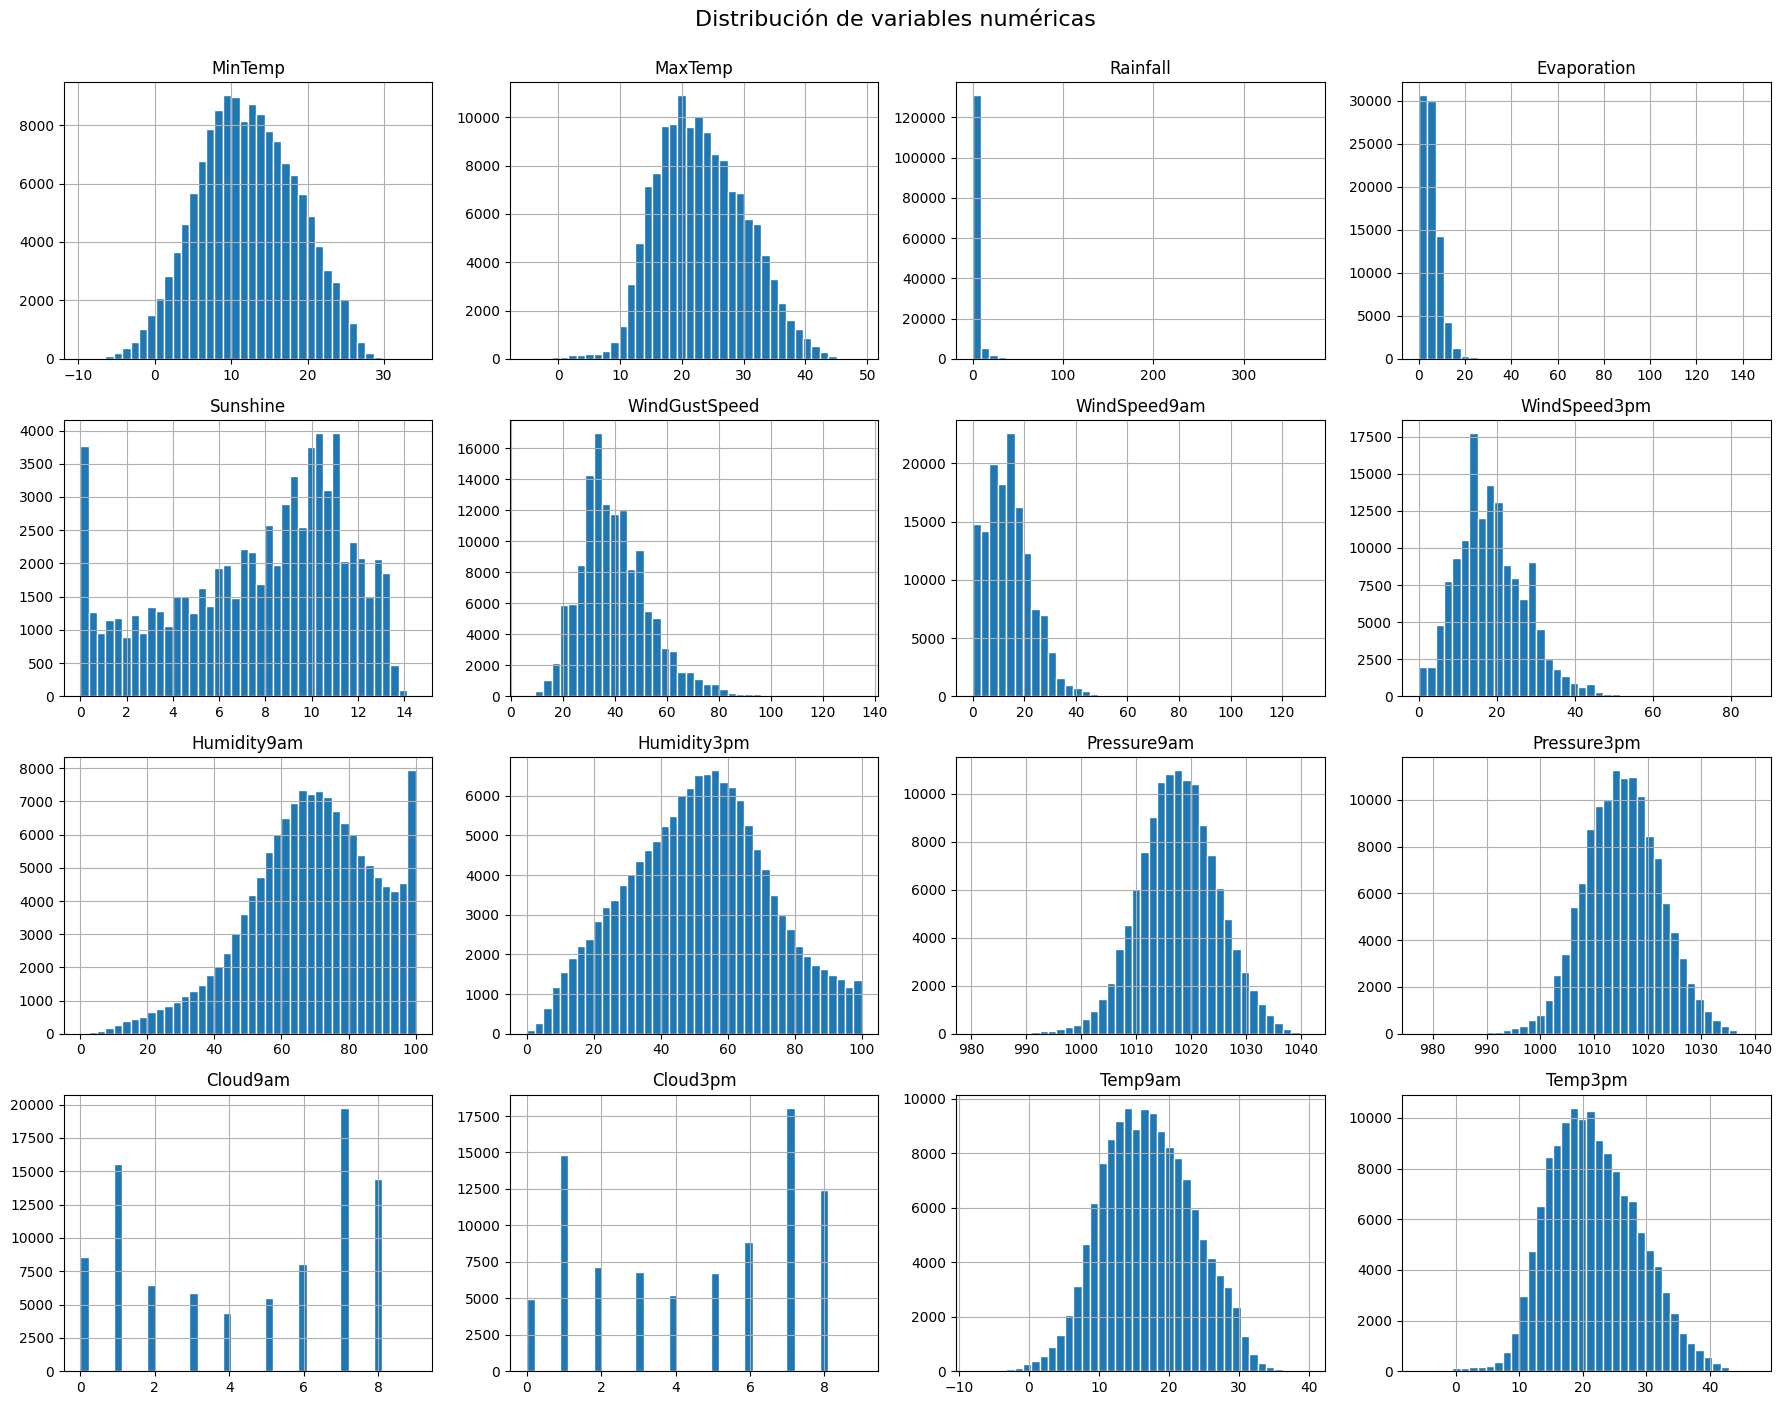

In [137]:
# Seleccionamos solo variables numéricas 
columnas_numericas = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                      'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                      'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                      'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

# Histogramas
df[columnas_numericas].hist(figsize=(18, 14), bins=40, edgecolor='white')
plt.suptitle('Distribución de variables numéricas', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

agregar comentario sobre las distribuciones

In [138]:
print('Valores únicos en Cloud9am:', sorted(df['Cloud9am'].dropna().unique()))
print('Valores únicos en Cloud3pm:', sorted(df['Cloud3pm'].dropna().unique()))

Valores únicos en Cloud9am: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]
Valores únicos en Cloud3pm: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]


In [139]:
# Cuántas observaciones tienen Cloud9am = 9
cant_9 = (df['Cloud9am'] == 9).sum()
total = df['Cloud9am'].notna().sum()
print(f'Cloud9am = 9: {cant_9} casos ({cant_9/total*100:.2f}% de los no-nulos)')


Cloud9am = 9: 2 casos (0.00% de los no-nulos)


In [140]:
# Cuántas observaciones tienen Cloud3pm = 9
cant_9 = (df['Cloud3pm'] == 9).sum()
total = df['Cloud3pm'].notna().sum()
print(f'Cloud3pm = 9: {cant_9} casos ({cant_9/total*100:.2f}% de los no-nulos)')

Cloud3pm = 9: 1 casos (0.00% de los no-nulos)


Se encuentran 3 valores fuera de rango dado que esta medido en octas, se decide reemplazar por el valor maximo posible en la escala

In [141]:
# Reemplazamos Cloud9am = 9 por 8 (escala oficial de octas es 0-8)
df.loc[df['Cloud9am'] == 9, 'Cloud9am'] = 8
df.loc[df['Cloud3pm'] == 9, 'Cloud3pm'] = 8
# Verificación
print('Valores únicos en Cloud9am después de la corrección:',
      sorted(df['Cloud9am'].dropna().unique()))
print('Valores únicos en Cloud3pm después de la corrección:',
      sorted(df['Cloud3pm'].dropna().unique()))

Valores únicos en Cloud9am después de la corrección: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
Valores únicos en Cloud3pm después de la corrección: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]


Analisis de variables numericas

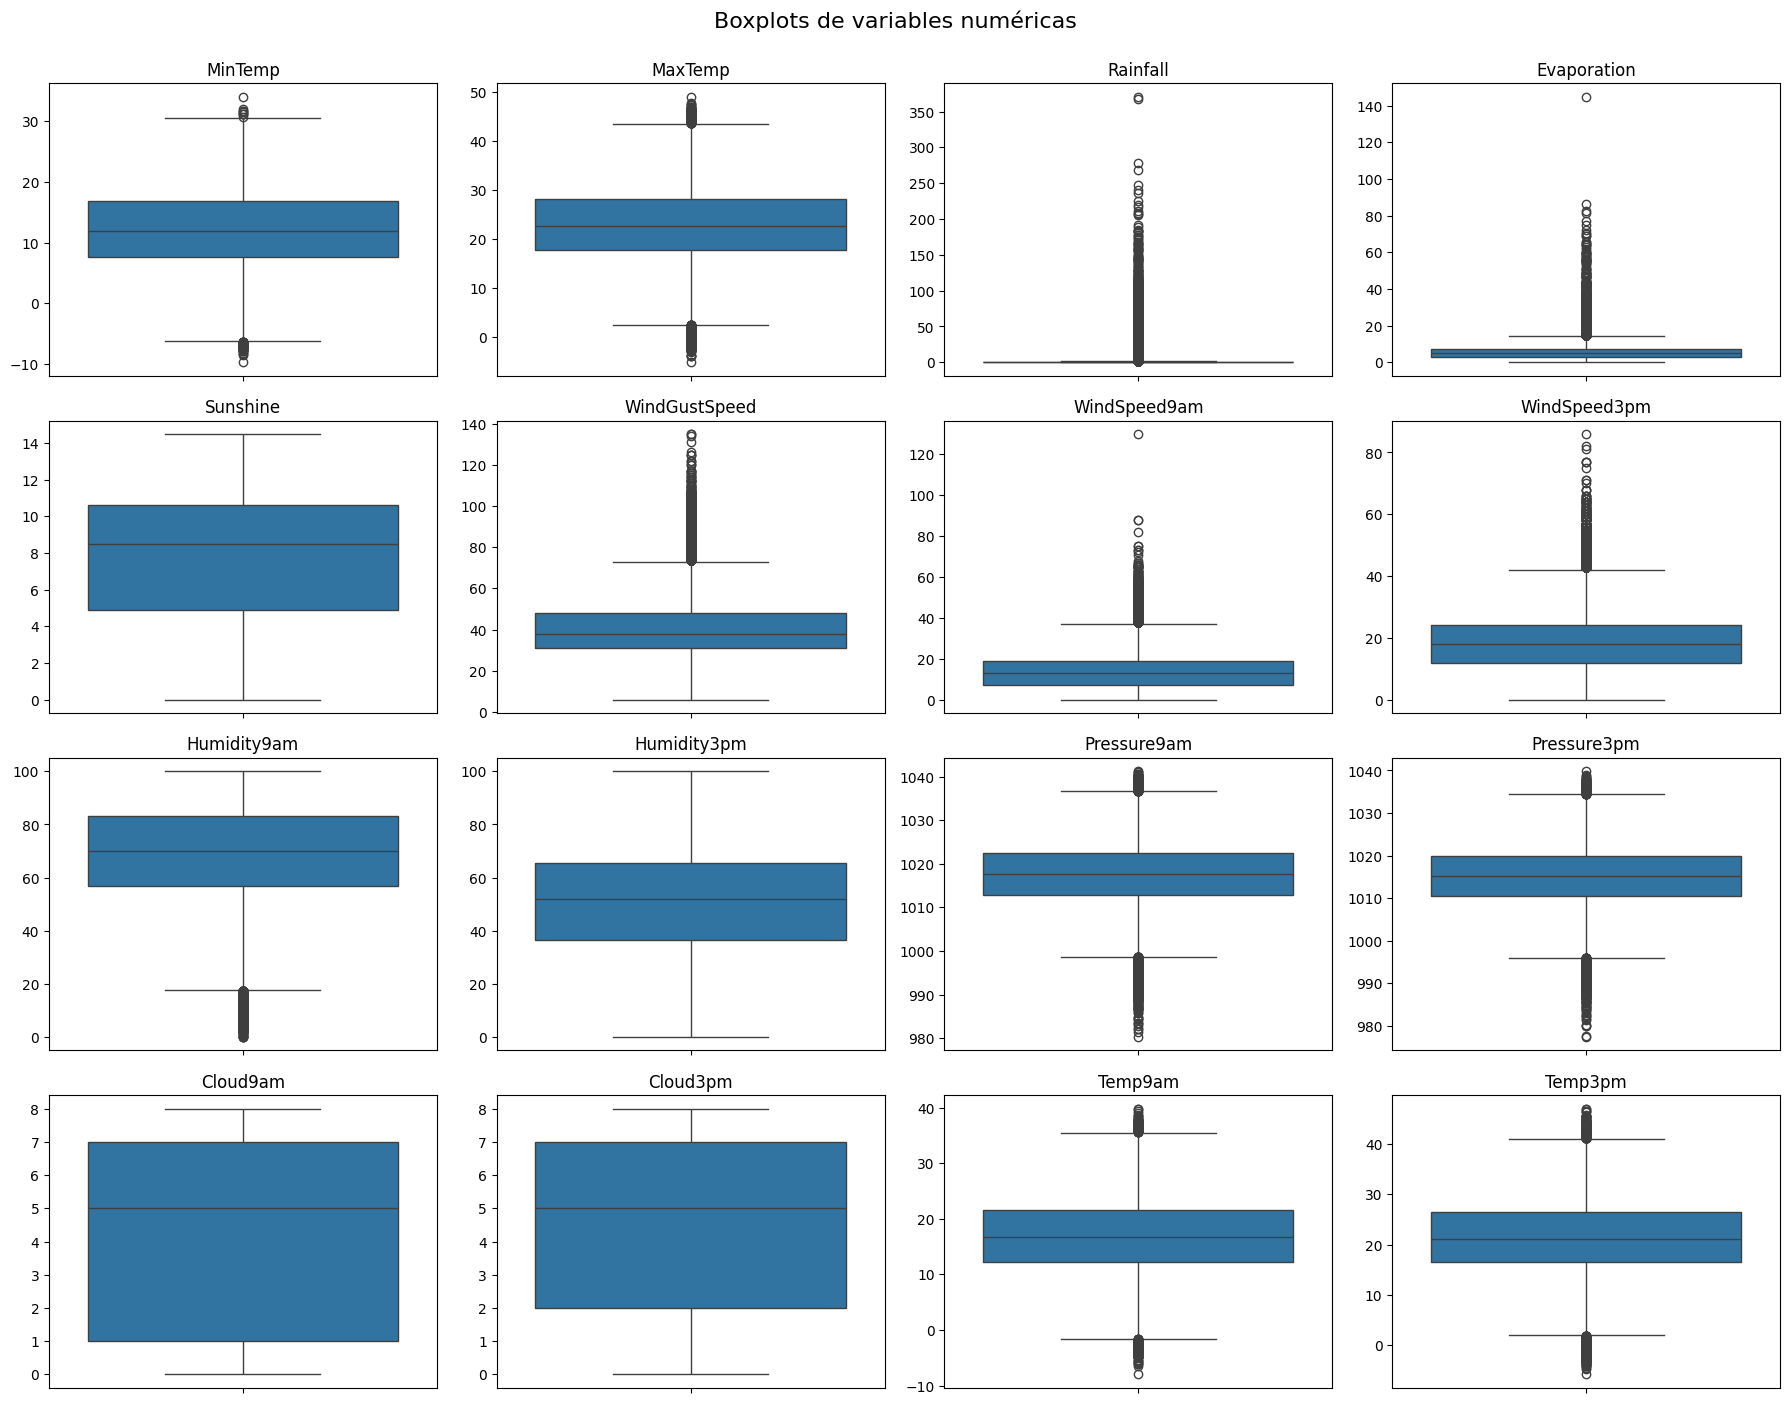

In [142]:
# Boxplots de todas las variables numéricas
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel('')

plt.suptitle('Boxplots de variables numéricas', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

Los diagramas de caja muestran la presencia de observaciones extremas, especialmente en `Rainfall`, que presenta una gran cantidad de valores atípicos. Dado que varias variables presentan outliers, esta visualización justifica el uso de un escalado robusto, ya que minimiza la influencia desproporcionada de esos valores sobre el modelo y permite una comparación más estable entre variables.

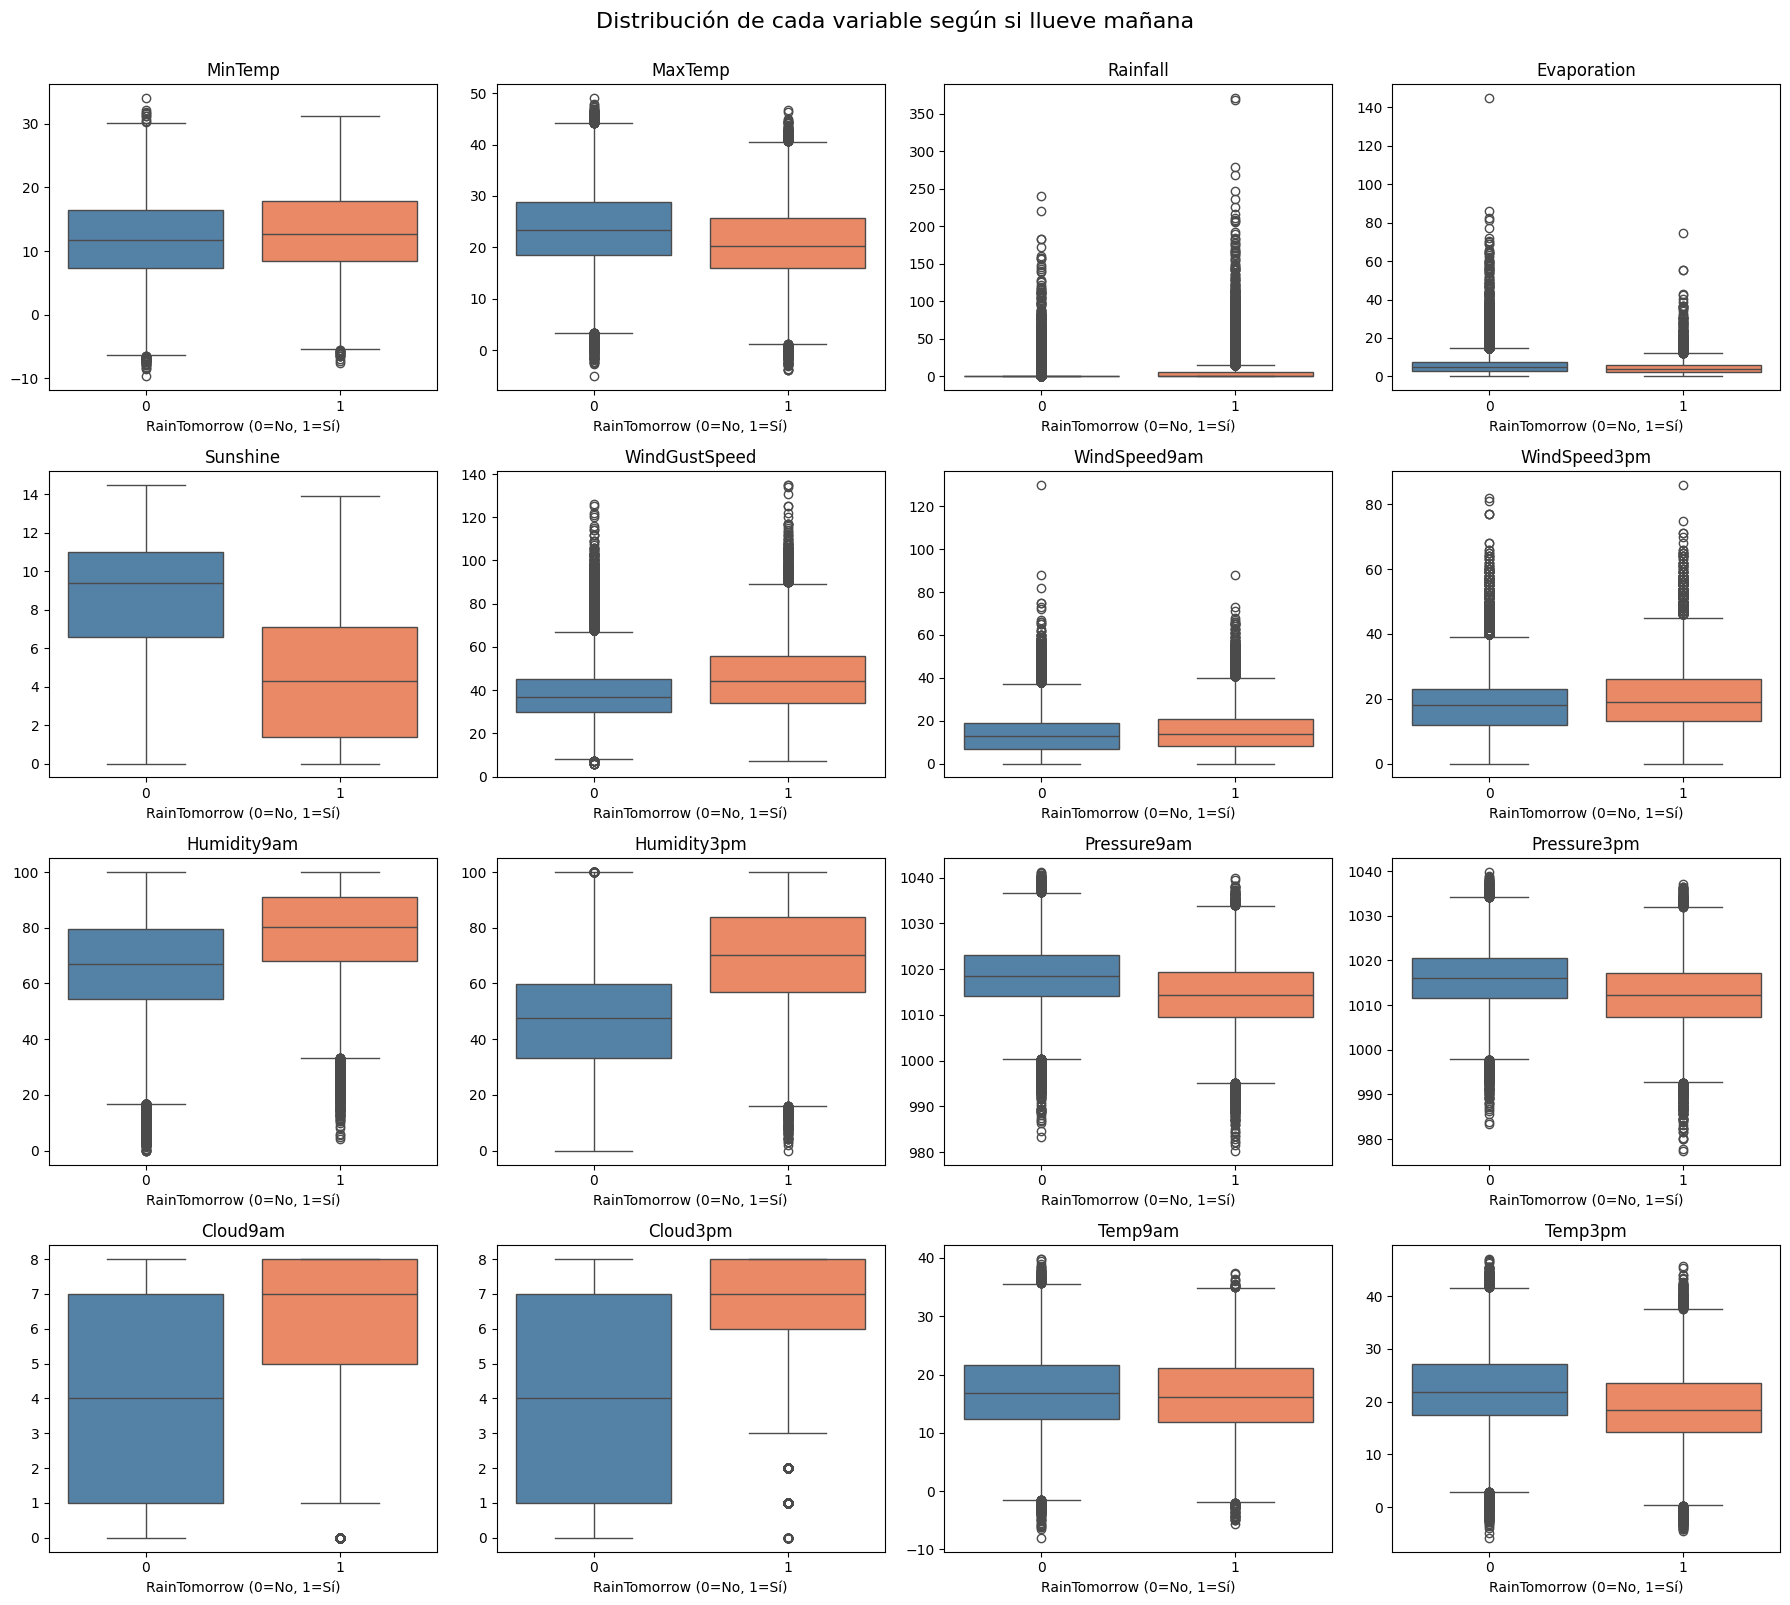

In [143]:
# Boxplots de cada variable numérica segmentados por RainTomorrow
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(columnas_numericas):
    sns.boxplot(
        data=df,
        x='RainTomorrow',
        y=col,
        ax=axes[i],
        hue='RainTomorrow',
        palette={0: 'steelblue', 1: 'coral'},
        legend=False
    )
    axes[i].set_title(f'{col}')
    axes[i].set_xlabel('RainTomorrow (0=No, 1=Sí)')
    axes[i].set_ylabel('')

plt.suptitle('Distribución de cada variable según si llueve mañana',
             fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

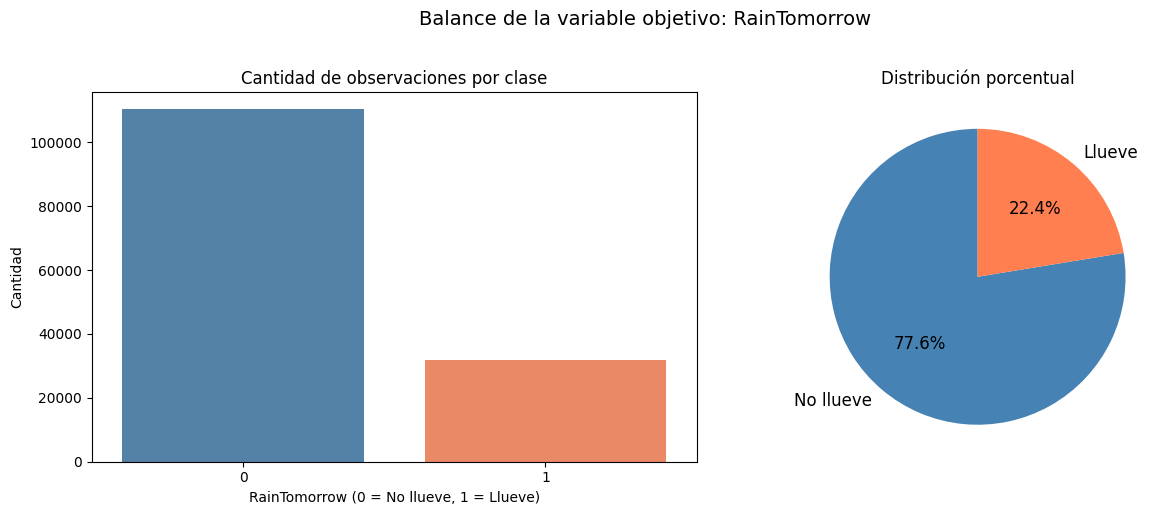

In [144]:
# Distribución de la variable objetivo
counts = df['RainTomorrow'].value_counts()
porcentajes = df['RainTomorrow'].value_counts(normalize=True) * 100

# Visualización del desbalance
fig, axes = plt.subplots(1, 2, figsize=(13, 5))


sns.countplot(x=df['RainTomorrow'], ax=axes[0],
              hue=df['RainTomorrow'],
              palette={0: 'steelblue', 1: 'coral'},
              legend=False)
axes[0].set_title('Cantidad de observaciones por clase')
axes[0].set_xlabel('RainTomorrow (0 = No llueve, 1 = Llueve)')
axes[0].set_ylabel('Cantidad')

axes[1].pie(counts,
            labels=['No llueve', 'Llueve'],
            colors=['steelblue', 'coral'],
            autopct='%1.1f%%',
            startangle=90,
            textprops={'fontsize': 12})
axes[1].set_title('Distribución porcentual')

plt.suptitle('Balance de la variable objetivo: RainTomorrow', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Se observa que el dataset esta desbalanceado

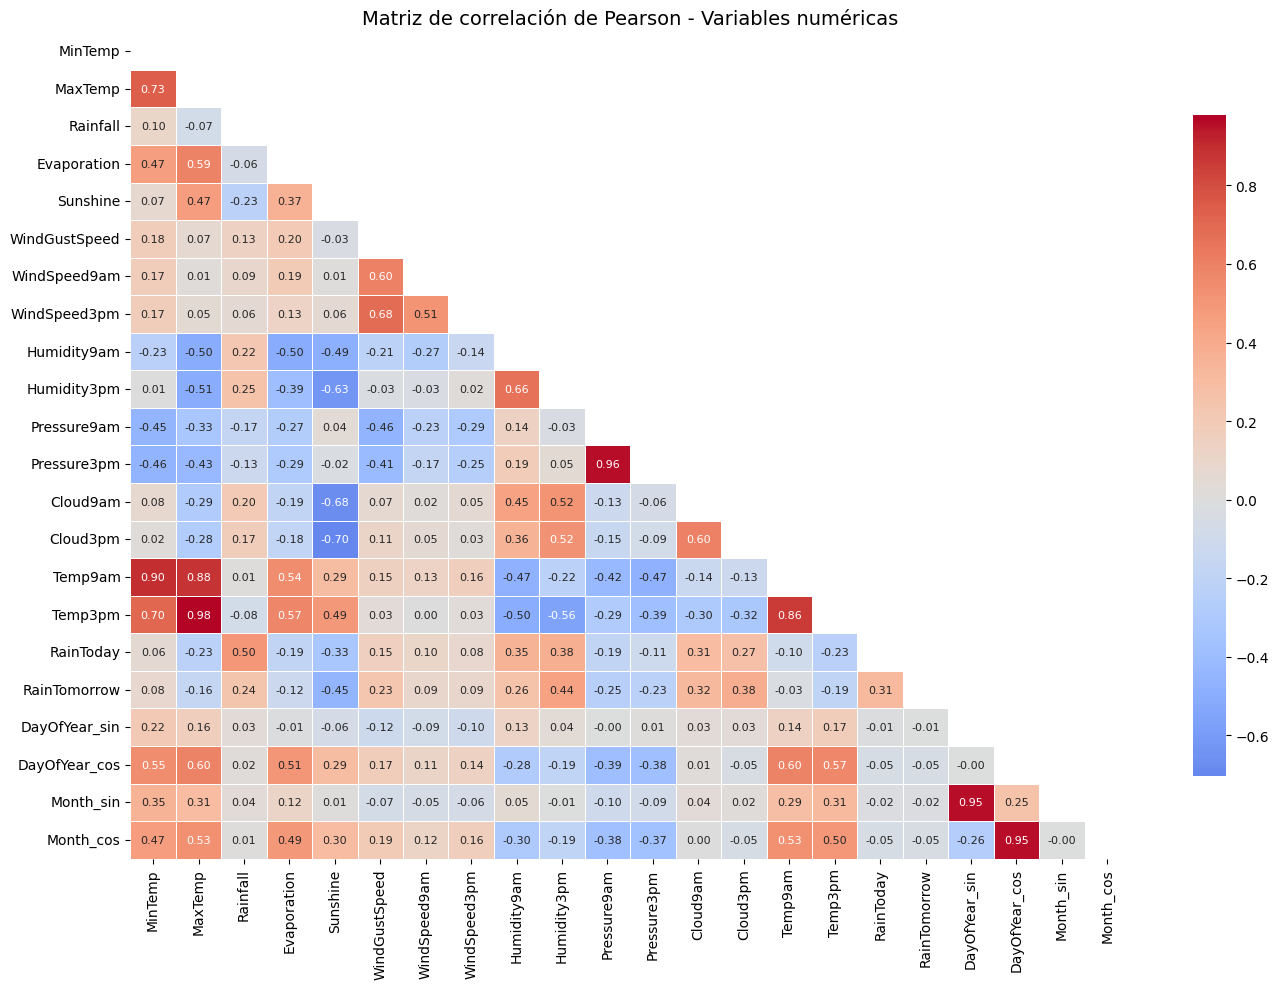

In [145]:
# Seleccionamos las variables numéricas para la matriz de correlación
columnas_correlacion = ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
                        'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm',
                        'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm',
                        'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm',
                        'RainToday', 'RainTomorrow',
                        'DayOfYear_sin', 'DayOfYear_cos','Month_sin', 'Month_cos']

# Calculamos correlación de Pearson
corr_matrix = df[columnas_correlacion].corr(method='pearson')

# Heatmap completo
plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # triángulo superior oculto
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', center=0,
            annot=True, fmt='.2f', annot_kws={'size': 8},
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlación de Pearson - Variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

Se observa alta correlación positiva entre MinTemp y MaxTemp, y entre Temp9am y Temp3pm, lo cual es esperable porque describen distintas mediciones de temperatura del mismo día.

Humidity3pm y Humidity9am también presentan una correlación elevada, indicando que aportan información similar.

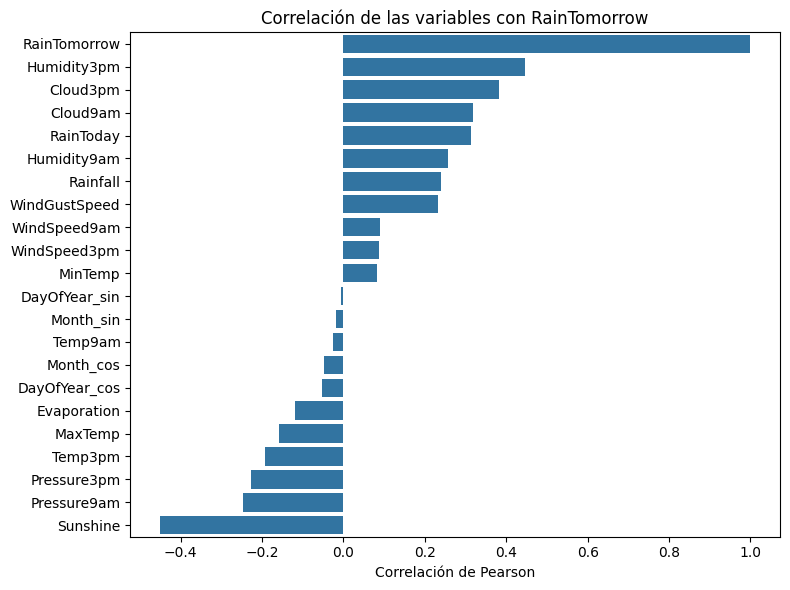

In [146]:
# Correlación de todas las features con la variable objetivo
corr_target = corr_matrix['RainTomorrow'].sort_values(ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(x=corr_target.values, y=corr_target.index)
plt.title("Correlación de las variables con RainTomorrow")
plt.xlabel("Correlación de Pearson")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [147]:
# la graficamos con valores absolutos para ver mejor las variables con baja correlación ?

Respecto de la variable objetivo RainTomorrow, las variables con mayor correlación positiva son RainToday, Humidity3pm y Cloud3pm, lo que es consistente con la intuición: si hoy llueve, la humedad a la tarde es alta y el cielo está nublado, aumenta la probabilidad de lluvia al día siguiente.

La mayoría de las demás variables tienen correlaciones débiles (cerca de 0), por lo que su relación lineal con la lluvia de mañana es baja. Esto no implica que sean inútiles, pero sí que, al menos bajo una medida lineal (Pearson), no aportan tanta información.

Codificacion de las variables relacionadas con la direccion del viento

In [148]:
columnas_viento = ['WindGustDir', 'WindDir9am', 'WindDir3pm']

for col in columnas_viento:
    print(f'Valores únicos en {col}:')
    print(df[col].unique())

Valores únicos en WindGustDir:
['NW' 'ENE' 'SSE' 'SE' 'E' 'S' 'N' 'WNW' 'ESE' 'NE' 'NNE' 'NNW' 'SW' 'W'
 'WSW' nan 'SSW']
Valores únicos en WindDir9am:
['SW' 'E' 'N' 'WNW' 'SSE' 'SE' 'S' 'WSW' 'NNE' 'NNW' 'ENE' 'SSW' 'NW'
 'ESE' 'NE' 'W' nan]
Valores únicos en WindDir3pm:
['NW' 'W' 'NNE' 'ESE' 'E' 'ENE' 'WSW' 'NE' 'NNW' 'SE' 'S' 'SW' 'WNW' 'N'
 'SSW' 'SSE' nan]


In [149]:
valores_por_columna = {
    col: set(df[col].dropna().unique())
    for col in columnas_viento
}

referencia = columnas_viento[0]
for col in columnas_viento[1:]:
    coinciden = valores_por_columna[referencia] == valores_por_columna[col]
    print(f'{referencia} vs. {col}: {"iguales" if coinciden else "diferentes"}')
    if not coinciden:
        print(f'  Solo en {referencia}: {sorted(valores_por_columna[referencia] - valores_por_columna[col])}')
        print(f'  Solo en {col}: {sorted(valores_por_columna[col] - valores_por_columna[referencia])}')

WindGustDir vs. WindDir9am: iguales
WindGustDir vs. WindDir3pm: iguales


se obtiene que tienen las mismas direcciones

In [ ]:
# Diccionario: dirección → ángulo en grados (16 puntos cardinales)
direccion_a_grados = {
    'N':   0,    'NNE': 22.5,  'NE':  45,    'ENE': 67.5,
    'E':   90,   'ESE': 112.5, 'SE':  135,   'SSE': 157.5,
    'S':   180,  'SSW': 202.5, 'SW':  225,   'WSW': 247.5,
    'W':   270,  'WNW': 292.5, 'NW':  315,   'NNW': 337.5
}

def codificar_direccion_ciclica(df, columna):
    """Codifica una columna de direcciones cardinales con sin/cos."""
    grados = df[columna].map(direccion_a_grados)
    radianes = np.deg2rad(grados)

    df[f'{columna}_sin'] = np.sin(radianes)
    df[f'{columna}_cos'] = np.cos(radianes)
    df.drop(columns=[columna], inplace=True)
    return df

columnas_viento = ['WindGustDir', 'WindDir9am', 'WindDir3pm']

for col in columnas_viento:
    df = codificar_direccion_ciclica(df, col)


print(f'df shape: {df.shape}')
print('\nColumnas nuevas en df:')
print([c for c in df.columns if 'sin' in c or 'cos' in c])
df.head()

df shape: (142153, 36)

Columnas nuevas en df:
['DayOfYear_sin', 'DayOfYear_cos', 'Month_sin', 'Month_cos', 'WindGustDir_sin', 'WindGustDir_cos', 'WindDir9am_sin', 'WindDir9am_cos', 'WindDir3pm_sin', 'WindDir3pm_cos']


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month,DayOfYear,DayOfYear_sin,DayOfYear_cos,Month_sin,Month_cos,Region_BOM,WindGustDir_sin,WindGustDir_cos,WindDir9am_sin,WindDir9am_cos,WindDir3pm_sin,WindDir3pm_cos
0,2007-11-01,Canberra,7.9,24.3,0.0,3.4,6.3,NW,29.0,SW,NW,7.0,20.0,63.9,28.1,1020.3,1014.7,7.0,7.0,14.4,23.5,0,1,11,305,-0.858764,0.512371,-0.5,0.866025,Templada,-0.707107,0.707107,-0.707107,-7.071068e-01,-0.707107,7.071068e-01
1,2007-11-02,Canberra,13.3,27.0,3.6,4.4,9.7,ENE,38.0,E,W,5.0,14.0,79.4,35.8,1012.1,1008.5,5.0,3.0,17.4,25.6,1,1,11,306,-0.849817,0.527078,-0.5,0.866025,Templada,0.923880,0.382683,1.000000,6.123234e-17,-1.000000,-1.836970e-16
2,2007-11-03,Canberra,13.9,23.1,3.6,5.8,3.3,NW,84.0,N,NNE,5.0,6.0,80.9,68.8,1009.6,1007.4,8.0,7.0,15.3,20.0,1,1,11,307,-0.840618,0.541628,-0.5,0.866025,Templada,-0.707107,0.707107,0.000000,1.000000e+00,0.382683,9.238795e-01
3,2007-11-04,Canberra,13.0,15.8,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,23.0,62.7,55.9,1005.4,1007.0,2.0,7.0,13.1,13.3,1,1,11,308,-0.831171,0.556017,-0.5,0.866025,Templada,-0.707107,0.707107,-0.923880,3.826834e-01,-1.000000,-1.836970e-16
4,2007-11-05,Canberra,7.8,16.4,2.8,5.6,10.6,SSE,49.0,SSE,ESE,19.0,28.0,67.5,50.1,1018.4,1018.6,7.0,7.0,11.4,15.9,1,0,11,309,-0.821477,0.570242,-0.5,0.866025,Templada,0.382683,-0.923880,0.382683,-9.238795e-01,0.923880,-3.826834e-01


### 1.4 División en train y test (se deja para mas abajo, para el momento antes de imputar valores)

Se realiza la division previo de analisis detallado, imputacion o escalamiento.

Todo lo que se calcula a partir de los datos (medianas para imputar, medias y desvíos para escalar, umbrales de decisión) se obtiene sólo de train, y validación y test se transforman con esos valores.

Al componerse los datos de una serie temporal, la division debe realizarse respecto a un corte en el tiempo. Si mezcláramos al azar, quedarían en train días inmediatamente anteriores y posteriores a los de test, que son muy similares. Por eso dividimos por fecha:

In [ ]:
# Se define la proporción de los conjuntos de datos
total_len = len(df)
train_end = int(total_len * 0.70)
val_end = int(total_len * (0.70 + 0.15))

# División de forma secuencial respetando la serie de tiempo
df_train = df.iloc[:train_end].copy()
df_val   = df.iloc[train_end:val_end].copy()
df_test  = df.iloc[val_end:].copy()

# Se muestra rangos de fechas y dimensiones
for name, dataset in [('Train', df_train), ('Validation', df_val), ('Test', df_test)]:
    print(f"{name}: {len(dataset)} muestras ({len(dataset)/total_len:.2%}) | "
          f"Desde {dataset['Date'].min().date()} hasta {dataset['Date'].max().date()}")



Train: 99507 muestras (70.00%) | Desde 2007-11-01 hasta 2015-01-12
Validation: 21323 muestras (15.00%) | Desde 2015-01-12 hasta 2016-04-07
Test: 21323 muestras (15.00%) | Desde 2016-04-07 hasta 2017-06-24


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,Month
99502,2015-01-12,Wollongong,18.9,23.1,21.6,NaN,NaN,SSW,54.0,SSW,...,79.3,1016.5,1014.5,8.0,8.0,20.3,21.1,Yes,Yes,1
99503,2015-01-12,BadgerysCreek,18.8,25.4,13.8,NaN,NaN,SSE,40.0,S,...,68.8,1016.0,1013.5,NaN,NaN,20.2,24.4,Yes,No,1
99504,2015-01-12,Perth,15.3,35.9,0.0,12.0,13.2,SW,38.0,ENE,...,21.1,1008.2,1006.0,0.0,0.0,27.1,31.9,No,No,1
99505,2015-01-12,SalmonGums,6.7,31.3,0.0,NaN,NaN,SE,47.0,NE,...,18.2,NaN,NaN,NaN,NaN,20.8,30.3,No,No,1
99506,2015-01-12,MountGambier,14.2,34.6,0.0,4.0,10.3,NE,45.0,E,...,30.8,1012.0,1006.8,1.0,6.0,21.6,32.8,No,Yes,1
